# Loading Dataset and CNN
*Updated by: Meizl Ann F. Manlupig*

This notebook is a runnable version of the "Loading Dataset and CNN" slide deck. It walks through:

1. Loading a Dogs vs. Cats image dataset with OpenCV
2. Preprocessing the images (grayscale, resize, shuffle)
3. Saving/loading the prepared data with `pickle`
4. Building and training a Convolutional Neural Network (CNN) with TensorFlow/Keras to classify dogs vs. cats

> **Before you run this notebook:** download the Kaggle "Dogs vs. Cats" dataset (e.g. `https://www.kaggle.com/c/dogs-vs-cats/data` or the mirrored `salader/dogs-vs-cats` dataset on Kaggle) and unzip it so you have two folders, `Dog/` and `Cat/`, each full of `.jpg` images. Then set `DATADIR` below to point at the parent folder that contains `Dog/` and `Cat/`.

## Requirements for Image Processing

- **GPU** (optional, speeds up training but not required)
- **OpenCV** (`cv2`) – for image processing
- **os module** – lets Python interface with the OS running on your computer (already in the standard library)
- **Data** – we'll use the Kaggle "Dogs vs. Cats" dataset

Run the cell below once to install the packages this notebook needs (skip it if they're already installed in your environment).

In [1]:
# Run this once if the packages below aren't already installed.
# %pip install opencv-python numpy matplotlib tensorflow

## Checking and installing OpenCV

The original slides show installing OpenCV through **Anaconda Navigator** (Environments tab → search `opencv` → Install). If you're not using Anaconda, the `pip install opencv-python` command in the cell above does the same thing.

## Calling the Necessary Modules

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

## Data Preparation

Set `DATADIR` to the folder on your machine that contains the `Dog` and `Cat` subfolders (this replaces the original slide's hard-coded Windows path, `C:/Users/admin/Desktop/AMEN/Deep_Learning_class/Kaggle_dataset/PetImages`, with something you can edit for your own machine).

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Unzipping the Dataset

Given that the dataset is in a `.zip` file in Google Drive, we need to unzip it to a local directory before processing. I'll unzip `PetImages.zip` to `/content/` and then set `DATADIR` to this new location.

In [4]:
!pip install -q gdown

import gdown

file_id = "1NLIaoMXrNmc68M3UNaFuC0Ewi7tQWDxz"

gdown.download(
    f"https://drive.google.com/uc?id={file_id}",
    "PetImages.zip",
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=1NLIaoMXrNmc68M3UNaFuC0Ewi7tQWDxz
From (redirected): https://drive.google.com/uc?id=1NLIaoMXrNmc68M3UNaFuC0Ewi7tQWDxz&confirm=t&uuid=5707cc01-c371-44ff-8df4-cff70db47c32
To: /content/PetImages.zip
100%|██████████| 827M/827M [00:11<00:00, 73.7MB/s]


'PetImages.zip'

In [5]:
import zipfile

with zipfile.ZipFile("PetImages.zip", "r") as zip_ref:
    zip_ref.extractall("/content/PetImages")

print("Done!")

Done!


### Programmatically Subsetting the Dataset to Reduce Size

To save storage space on Google Drive, we can create a much smaller, balanced subset (e.g., 1,000 dogs and 1,000 cats) of the original unzipped dataset and compress it into a new ZIP archive.

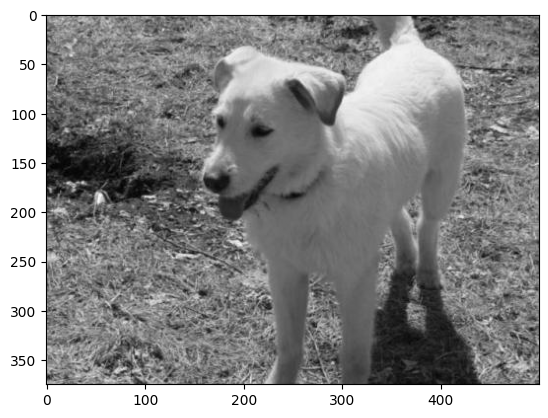

In [6]:
DATADIR = "/content/PetImages/PetImages"  # <- change this to the path that contains your Dog/ and Cat/ folders
# this is the directory of your datasets
CATEGORIES = ["Dog", "Cat"]   # Defining the label as "Dog" or "Cat"

for category in CATEGORIES:
    path = os.path.join(DATADIR, category)  # path to cats or dogs dir
    for img in os.listdir(path):
        img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
        if img_array is None:
            # a handful of files in the Kaggle dataset are corrupted/unreadable - skip them
            continue

        # reading the image in the path and transforming it into an array
        # cv2.IMREAD_GRAYSCALE converts the image to grayscale so the CNN only has
        # to learn from one color channel instead of three (faster, smaller model)

        plt.imshow(img_array, cmap="gray")
        plt.show()
        break
    break

In [7]:
import os
import shutil
import random
import zipfile

# Corrected Source directory
source_dir = "/content/PetImages/PetImages"
categories = ["Dog", "Cat"]

# Destination directories for the smaller subset
subset_dir = "/content/PetImages_Subsampled"
os.makedirs(subset_dir, exist_ok=True)

# Define how many images per category you want to keep
images_per_category = 1000

for category in categories:
    src_path = os.path.join(source_dir, category)
    dest_path = os.path.join(subset_dir, category)
    os.makedirs(dest_path, exist_ok=True)

    # Get all valid images
    all_imgs = [img for img in os.listdir(src_path) if img.lower().endswith(('.jpg', '.jpeg', '.png'))]

    # Randomly sample the images
    sampled_imgs = random.sample(all_imgs, min(images_per_category, len(all_imgs)))

    # Copy the selected files
    for img in sampled_imgs:
        shutil.copy(os.path.join(src_path, img), os.path.join(dest_path, img))

print(f"Created a subset at '{subset_dir}' with {images_per_category} images per class.")

Created a subset at '/content/PetImages_Subsampled' with 1000 images per class.


In [8]:
# Compress the subsetted folder into a smaller ZIP file
zip_output_path = "/content/PetImages_Small.zip"

with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zip_file:
    for root, dirs, files in os.walk(subset_dir):
        for file in files:
            file_path = os.path.join(root, file)
            # Save files relative to subset_dir
            arcname = os.path.relpath(file_path, subset_dir)
            zip_file.write(file_path, arcname)

print(f"Successfully compressed the subset dataset into: {zip_output_path}")
print(f"Zip size: {os.path.getsize(zip_output_path) / (1024 * 1024):.2f} MB")

Successfully compressed the subset dataset into: /content/PetImages_Small.zip
Zip size: 61.17 MB


## Image Inspection

In [9]:
print(img_array)          # Displaying the image in array form (just for checking)
print(img_array.shape)    # checking the resolution of the image

[[155 157 159 ... 120 128 135]
 [142 154 165 ... 123 128 132]
 [142 156 168 ... 125 130 136]
 ...
 [176 173 147 ...  93  92  82]
 [177 185 160 ... 101 102 103]
 [162 182 162 ...  78  62  59]]
(375, 500)


## Image Resizing

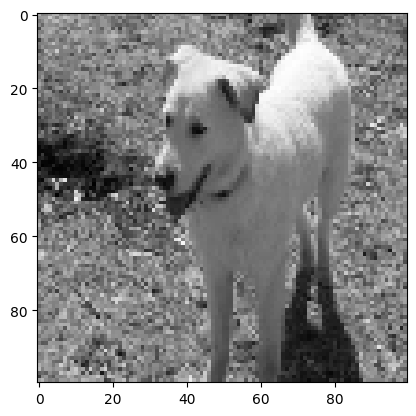

In [10]:
IMG_SIZE = 100  # initializing variable "IMG_SIZE" as 100

new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
plt.imshow(new_array, cmap='gray')
plt.show()

## Assigning Training Data

In [11]:
training_data = []  # assigning training data

def create_training_data():
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)  # path to cats or dogs dir
        class_num = CATEGORIES.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
                new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                training_data.append([new_array, class_num])
            except Exception as e:
                pass

create_training_data()

## Checking the Number of Training Data

In [12]:
print(len(training_data))

24997


## Randomizing/Shuffling the Data

In [13]:
import random
random.shuffle(training_data)

for sample in training_data[:10]:
    print(sample[1])

0
0
1
0
0
0
1
1
1
1


## Assigning Variables for Features and Labels

In [14]:
X = []  # feature set
y = []  # labels

for features, label in training_data:
    X.append(features)
    y.append(label)

X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)  # 1 is for grayscale
y = np.array(y)  # Keras expects the labels as an array too

## Using the Pickle Module

In [15]:
import pickle  # pickle lets you save your training data, avoiding recreating it
                # from scratch every time you want to adjust the model

with open('X.pickle', 'wb') as f:
    pickle.dump(X, f)

with open('y.pickle', 'wb') as g:
    pickle.dump(y, g)

## Using Pickle (Loading It Back)

In [16]:
pickle_in = open('X.pickle', 'rb')
X = pickle.load(pickle_in)

X[1]

array([[[181],
        [174],
        [157],
        ...,
        [240],
        [237],
        [186]],

       [[218],
        [186],
        [213],
        ...,
        [232],
        [234],
        [190]],

       [[204],
        [197],
        [210],
        ...,
        [203],
        [211],
        [197]],

       ...,

       [[ 61],
        [ 14],
        [ 24],
        ...,
        [ 55],
        [ 44],
        [ 62]],

       [[  6],
        [ 34],
        [ 37],
        ...,
        [ 50],
        [ 59],
        [ 68]],

       [[ 71],
        [ 27],
        [ 26],
        ...,
        [ 36],
        [ 71],
        [ 79]]], dtype=uint8)

## What is a CNN?

**CNN** stands for **Convolutional Neural Network** — a type of neural network especially well suited to image data because it learns spatial patterns (edges, textures, shapes) through convolution and pooling layers instead of treating every pixel independently.

Further reading:
- https://medium.com/data-science-group-iitr/building-a-convolutional-neural-network-in-python-with-tensorflow-d251c3ca8117
- https://hackernoon.com/what-is-a-capsnet-or-capsule-network-2bfbe48769cc

## Using a CNN for Classification of Images

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D
import pickle

X = pickle.load(open('X.pickle', 'rb'))
y = pickle.load(open('y.pickle', 'rb'))

## Building, Compiling, and Training the CNN

`X = X/255.0` normalizes the pixel values (0-255) down to the 0-1 range, which helps the network train faster and more stably.

> Training for the full 200 epochs on the whole dataset can take a long time on CPU. Reduce `epochs` (e.g. to 10) for a quick test run, and increase it back up once you know the pipeline works.

In [18]:
X = X / 255.0

model = Sequential()
model.add(Input(shape=X.shape[1:]))
##Edited
#Conv Layer 1
model.add(Conv2D(32,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))
#Conv Layer 2
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))
#Conv Layer 3
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))

#Flatten
model.add(Flatten())
#Dense
model.add(Dense(64, activation='relu'))
#Dropout
model.add(Dropout(0.5))
# Output
model.add(Dense(1))
model.add(Activation('sigmoid'))

model.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.Adam(
              learning_rate=0.001),
              metrics=['accuracy']
              )



In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       819,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 912,001 (3.48 MB)

 Trainable params: 912,001 (3.48 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history = model.fit(X, y, batch_size=32, epochs=20, validation_split=0.2)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 427s 681ms/step - accuracy: 0.6576 - loss: 0.6140 - val_accuracy: 0.7392 - val_loss: 0.5231
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 420s 672ms/step - accuracy: 0.7727 - loss: 0.4862 - val_accuracy: 0.7882 - val_loss: 0.4512
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 446s 679ms/step - accuracy: 0.8113 - loss: 0.4183 - val_accuracy: 0.8296 - val_loss: 0.3742
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 431s 662ms/step - accuracy: 0.8415 - loss: 0.3620 - val_accuracy: 0.8334 - val_loss: 0.3782
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 403s 645ms/step - accuracy: 0.8647 - loss: 0.3173 - val_accuracy: 0.8536 - val_loss: 0.3361
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 430s 687ms/step - accuracy: 0.8838 - loss: 0.2773 - val_accuracy: 0.8584 - val_loss: 0.3237
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 429s 687ms/step - accuracy: 0.8989 - loss: 0.2399 - val_accuracy: 0.8560 - val_loss: 0.3520
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 440s 684ms/step - accuracy: 0.9140 -

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       819,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,736,005 (10.44 MB)

 Trainable params: 912,001 (3.48 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,824,004 (6.96 MB)

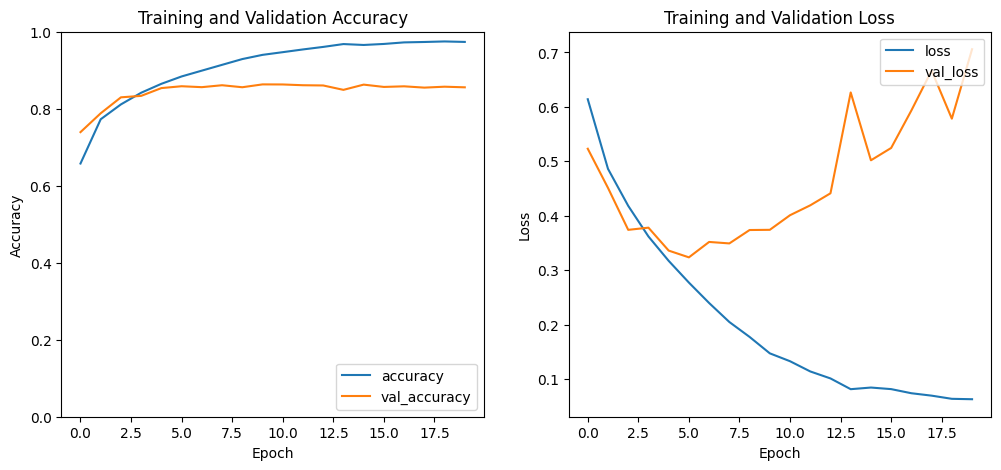

782/782 ━━━━━━━━━━━━━━━━━━━━ 129s 164ms/step

Confusion Matrix:
[[11985   514]
 [  316 12182]]


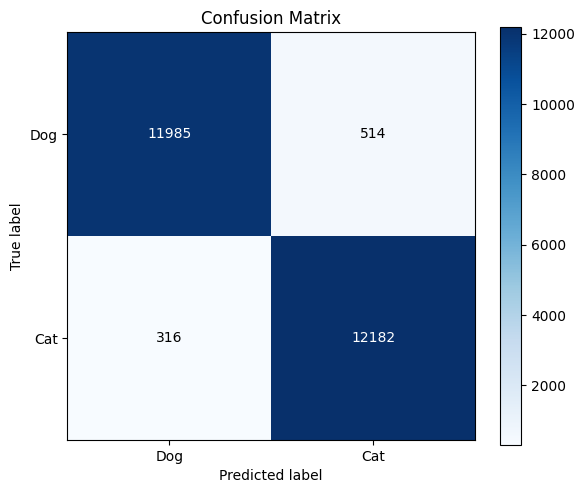

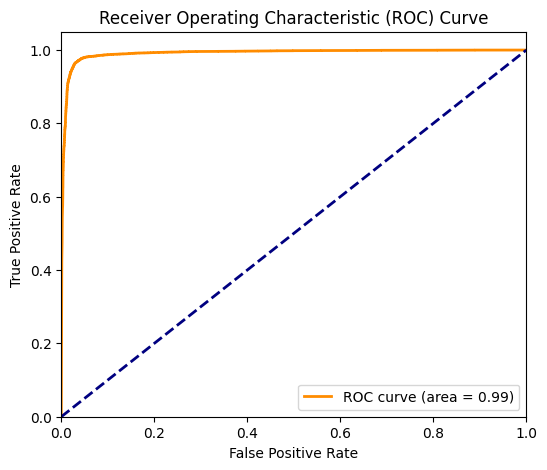

In [21]:
model.summary()

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc
import numpy as np # numpy is already imported as np earlier

# Plot training accuracy and loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

# Get predictions for confusion matrix and ROC
y_pred_proba = model.predict(X).ravel() # .ravel() to flatten to 1D array
y_pred = (y_pred_proba > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y, y_pred)
print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(np.unique(y)))
CATEGORIES = ["Dog", "Cat"]
plt.xticks(tick_marks, CATEGORIES)
plt.yticks(tick_marks, CATEGORIES)
plt.ylabel('True label')
plt.xlabel('Predicted label')
fmt = 'd'
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, format(cm[i, j], fmt),
             ha="center", va="center",
             color="white" if cm[i, j] > thresh else "black")
plt.tight_layout()
plt.show()

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [22]:
import tensorflow as tf

# Define the filename for your model
model_filename = 'dog_cat_classifier.keras' # .keras is the recommended extension for Keras models

# Save the model
model.save(model_filename)
print(f"Model saved to {model_filename}")

# To load the model later (you can do this in a new session or script)
loaded_model = tf.keras.models.load_model(model_filename)
print(f"Model loaded from {model_filename}")

# You can then use the loaded_model for predictions or further evaluation
# For example, let's make predictions with the loaded model and compare
loaded_model_predictions = loaded_model.predict(X)
print("\nExample predictions from loaded model:")
print(loaded_model_predictions[:5])


Model saved to dog_cat_classifier.keras
Model loaded from dog_cat_classifier.keras
782/782 ━━━━━━━━━━━━━━━━━━━━ 127s 162ms/step

Example predictions from loaded model:
[[5.4293112e-03]
 [4.9023350e-13]
 [9.9992716e-01]
 [8.9439936e-07]
 [1.5541193e-03]]


## Prediction Inference

Now that the model is loaded, we can use it to make predictions on new, unseen data. For demonstration purposes, I'll take a few samples from your existing `X` data to illustrate how to get predictions from the `loaded_model`.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Predictions for the test samples:
Sample 1: Predicted Class = Dog (Probability: 0.54%) 
Sample 2: Predicted Class = Dog (Probability: 0.00%) 
Sample 3: Predicted Class = Cat (Probability: 99.99%) 
Sample 4: Predicted Class = Dog (Probability: 0.00%) 
Sample 5: Predicted Class = Dog (Probability: 0.16%) 


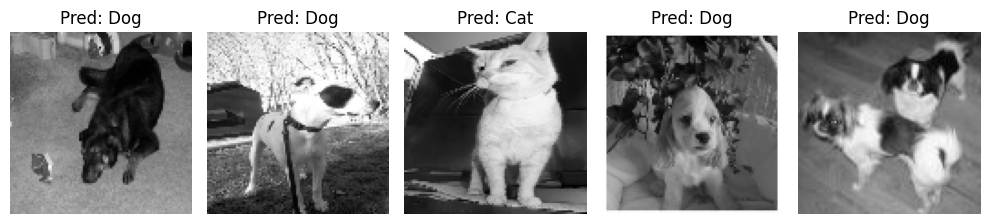

In [23]:
# Select a small subset of data for inference (e.g., the first 5 samples)
# In a real scenario, this would be entirely new, unseen test data.
test_samples = X[:5]

# Make predictions using the loaded model
inference_predictions = loaded_model.predict(test_samples)

print("Predictions for the test samples:")
for i, prediction in enumerate(inference_predictions):
    # Assuming binary classification with sigmoid output, values close to 1 are 'Cat', close to 0 are 'Dog'
    predicted_class = 'Cat' if prediction[0] > 0.5 else 'Dog'
    probability = prediction[0] * 100
    print(f"Sample {i+1}: Predicted Class = {predicted_class} (Probability: {probability:.2f}%) ")

# Optionally, display the images and their predictions
plt.figure(figsize=(10, 4))
for i in range(min(5, len(test_samples))):
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_samples[i].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
    predicted_class = 'Cat' if inference_predictions[i][0] > 0.5 else 'Dog'
    plt.title(f"Pred: {predicted_class}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## Hyperparameter Optimization with Keras Tuner

The CNN above used one fixed, hand-picked set of hyperparameters (a very thin first conv layer with only 2 filters, no dropout, a single learning rate, and a batch size chosen without any experimentation). This section uses [Keras Tuner](https://keras.io/keras_tuner/) to search over several hyperparameters automatically and picks the configuration that gets the best validation accuracy, instead of guessing.

Hyperparameters tuned in this section:

- **Number of convolutional blocks** (2–4)
- **Filters per convolutional layer** (32–256, in steps of 32)
- **Kernel size per convolutional layer** (3×3 or 5×5)
- **Number of dense layers** (1–2) and their **width** (32–256 units)
- **Dropout rate** (0.0–0.5) — the original model had no dropout at all, which is a common cause of overfitting
- **Learning rate** (1e-4 to 1e-2, sampled on a log scale)
- **Optimizer** (Adam vs. RMSprop)
- **Batch size** (32, 64, or 128)

> **Compute note:** hyperparameter search trains many candidate models, so it takes noticeably longer than training a single model. On Colab, switch to a GPU runtime (Runtime → Change runtime type → GPU) before running the cells below. If you just want to see the mechanism work, lower `max_epochs` in the tuner and `epochs` in `tuner.search(...)` first, then raise them once you know it runs end to end.

In [24]:
# Run this once if keras-tuner isn't already installed.
%pip install -q keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 3.6 MB/s eta 0:00:00


In [25]:
import keras_tuner as kt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

# Keras Tuner re-splits data internally across trials, but we hold out one fixed
# validation set so every trial (and the final tuned model) is judged on the same
# unseen data, making the comparison fair.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]} samples | Validation: {X_val.shape[0]} samples")

Train: 19997 samples | Validation: 5000 samples


In [26]:
def build_model(hp):
    """Builds a CNN whose architecture and optimizer are controlled by `hp`."""
    model = Sequential()
    model.add(Input(shape=X.shape[1:]))

    # Number of convolutional blocks: 2 to 4
    n_conv_layers = hp.Int("n_conv_layers", min_value=2, max_value=4, step=1)

    for i in range(n_conv_layers):
        filters = hp.Int(f"filters_{i}", min_value=32, max_value=256, step=32)
        kernel_size = hp.Choice(f"kernel_size_{i}", values=[3, 5])
        model.add(Conv2D(filters, (kernel_size, kernel_size), padding="same"))
        model.add(Activation("relu"))
        model.add(MaxPooling2D(pool_size=(2, 2)))

    model.add(Flatten())

    # Number of dense layers: 1 to 2, each with its own tunable width
    n_dense_layers = hp.Int("n_dense_layers", min_value=1, max_value=2, step=1)
    for j in range(n_dense_layers):
        dense_units = hp.Int(f"dense_units_{j}", min_value=32, max_value=256, step=32)
        model.add(Dense(dense_units))
        model.add(Activation("relu"))

    # Dropout to fight overfitting - the original model had none
    dropout_rate = hp.Float("dropout_rate", min_value=0.0, max_value=0.5, step=0.1)
    model.add(Dropout(dropout_rate))

    model.add(Dense(1))
    model.add(Activation("sigmoid"))

    learning_rate = hp.Float("learning_rate", min_value=1e-4, max_value=1e-2, sampling="log")
    optimizer_choice = hp.Choice("optimizer", values=["adam", "rmsprop"])

    if optimizer_choice == "adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)

    model.compile(loss="binary_crossentropy", optimizer=optimizer, metrics=["accuracy"])
    return model


class CNNHyperModel(kt.HyperModel):
    """Wraps build_model so batch size can be tuned alongside architecture."""

    def build(self, hp):
        return build_model(hp)

    def fit(self, hp, model, *args, **kwargs):
        batch_size = hp.Choice("batch_size", values=[32, 64, 128])
        return model.fit(*args, batch_size=batch_size, **kwargs)

In [27]:
from tensorflow.keras.callbacks import EarlyStopping

# Highly aggressive early stopping to terminate stagnating trials quickly
aggressive_stop = EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

In [29]:
# Setting max_trials=5 means the tuner will build and test exactly 5 model variations
tuner_limited = kt.RandomSearch(
    CNNHyperModel(),
    objective="val_accuracy",
    max_trials=5,
    executions_per_trial=1,
    directory="kt_dir",
    project_name="dogs_vs_cats_random_limited",
    overwrite=True
)

tuner_limited.search_space_summary()

# Run search with early stopping to save even more time
tuner_limited.search(
    X_train[:5000],
    y_train[:5000],
    validation_data=(X_val[:1000], y_val[:1000]),
    epochs=2, # Keep epochs low per trial for quick testing
    callbacks=[aggressive_stop],
    verbose=1
)

Trial 5 Complete [00h 18m 46s]
val_accuracy: 0.515999972820282

Best val_accuracy So Far: 0.6399999856948853
Total elapsed time: 01h 43m 56s


### Configuring Highly Aggressive Early Stopping

If you want to stop training a trial almost immediately when validation loss starts to rise or plateau, you can set `patience=1`.

### Alternative: Limit Trials using Random Search

If you want a predictable and hard-capped number of total trials (e.g. exactly 5 trials), you can use `kt.RandomSearch` or `kt.BayesianOptimization` instead of `Hyperband`:

In [33]:
# Use tuner_limited instead of tuner, as it was the one used during the search
best_hp = tuner_limited.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters found:")
for param, value in best_hp.values.items():
    print(f"  {param}: {value}")

Best hyperparameters found:
  n_conv_layers: 3
  filters_0: 32
  kernel_size_0: 3
  filters_1: 160
  kernel_size_1: 5
  n_dense_layers: 1
  dense_units_0: 256
  dropout_rate: 0.1
  learning_rate: 0.007776427195474676
  optimizer: adam
  filters_2: 32
  kernel_size_2: 3
  batch_size: 32


## Training the Tuned Model

We rebuild a fresh model with the winning hyperparameters and train it for longer, this time with two callbacks the original notebook didn't use:

- **`EarlyStopping`** stops training once validation loss stops improving, restoring the best weights seen — this avoids wasting epochs (and overfitting) once the model has plateaued.
- **`ReduceLROnPlateau`** halves the learning rate when validation loss stalls, which often squeezes out a bit more accuracy near the end of training.

In [37]:
# Use tuner_limited here since it contains our completed search results
best_model = tuner_limited.hypermodel.build(best_hp)
tuned_batch_size = best_hp.get("batch_size")

# Shorten run: Aggressive early stopping (patience=1) to stop quickly if it stalls
early_stop = EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6)

tuned_history = best_model.fit(
    X_train[:2000],  # Reduced training samples for a much faster run
    y_train[:2000],
    validation_data=(X_val[:500], y_val[:500]),  # Reduced validation samples
    batch_size=tuned_batch_size,
    epochs=5,        # Hard-capped at 5 epochs for a shorter run
    callbacks=[early_stop, reduce_lr],
)

Epoch 1/2
157/157 ━━━━━━━━━━━━━━━━━━━━ 308s 2s/step - accuracy: 0.5008 - loss: 0.8888 - val_accuracy: 0.4840 - val_loss: 0.6947 - learning_rate: 0.0078
Epoch 2/2
157/157 ━━━━━━━━━━━━━━━━━━━━ 324s 2s/step - accuracy: 0.5084 - loss: 0.6932 - val_accuracy: 0.5160 - val_loss: 0.6928 - learning_rate: 0.0078


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 100, 100, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 50, 50, 160)    │       128,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 50, 50, 160)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 25, 25, 160)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 25, 25, 32)     │        46,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,064,261 (15.50 MB)

 Trainable params: 1,354,753 (5.17 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,709,508 (10.34 MB)

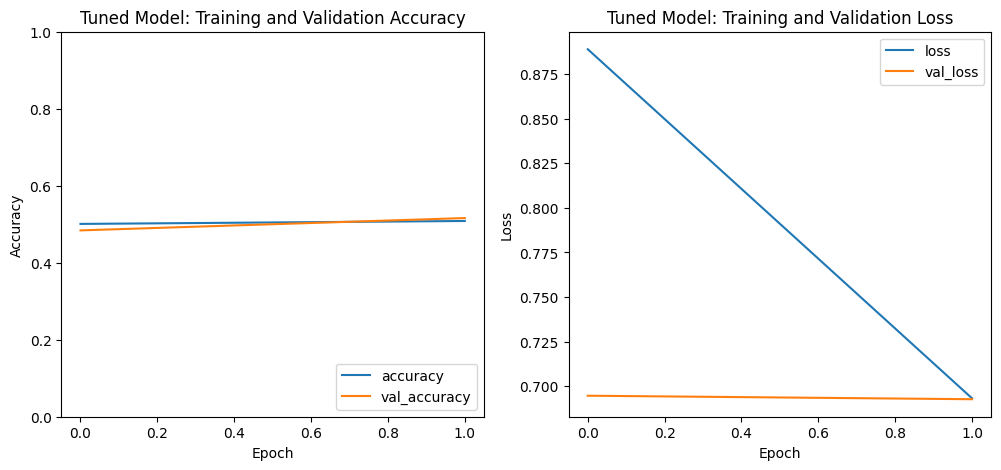

157/157 ━━━━━━━━━━━━━━━━━━━━ 88s 559ms/step

Tuned Model Confusion Matrix (validation set):
[[   0 2500]
 [   0 2500]]


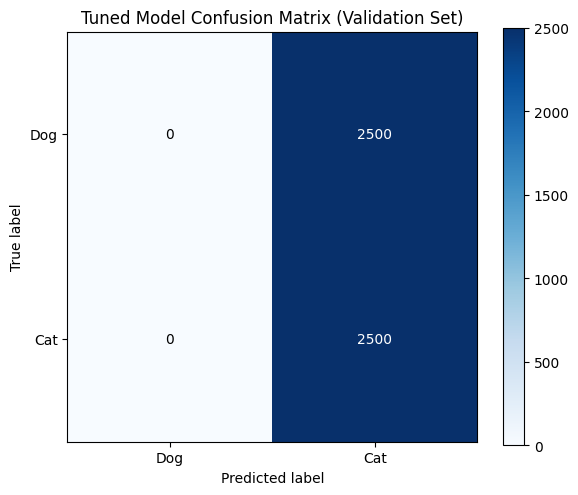

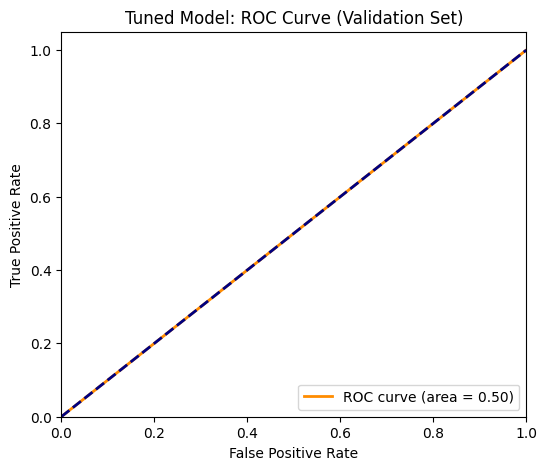

In [38]:
best_model.summary()

# Plot tuned model's training accuracy and loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(tuned_history.history['accuracy'], label='accuracy')
plt.plot(tuned_history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title('Tuned Model: Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(tuned_history.history['loss'], label='loss')
plt.plot(tuned_history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Tuned Model: Training and Validation Loss')

plt.show()

# Evaluate on the held-out validation split (never used for training or search decisions
# beyond early stopping/LR scheduling, so this is a fair estimate of generalization)
val_pred_proba = best_model.predict(X_val).ravel()
val_pred = (val_pred_proba > 0.5).astype(int)

cm_tuned = confusion_matrix(y_val, val_pred)
print("\nTuned Model Confusion Matrix (validation set):")
print(cm_tuned)

plt.figure(figsize=(6, 5))
plt.imshow(cm_tuned, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Tuned Model Confusion Matrix (Validation Set)')
plt.colorbar()
tick_marks = np.arange(len(CATEGORIES))
plt.xticks(tick_marks, CATEGORIES)
plt.yticks(tick_marks, CATEGORIES)
plt.ylabel('True label')
plt.xlabel('Predicted label')
thresh = cm_tuned.max() / 2.
for i, j in np.ndindex(cm_tuned.shape):
    plt.text(j, i, format(cm_tuned[i, j], 'd'),
             ha="center", va="center",
             color="white" if cm_tuned[i, j] > thresh else "black")
plt.tight_layout()
plt.show()

fpr_tuned, tpr_tuned, _ = roc_curve(y_val, val_pred_proba)
roc_auc_tuned = auc(fpr_tuned, tpr_tuned)

plt.figure(figsize=(6, 5))
plt.plot(fpr_tuned, tpr_tuned, color='darkorange', lw=2,
         label=f'ROC curve (area = {roc_auc_tuned:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Tuned Model: ROC Curve (Validation Set)')
plt.legend(loc="lower right")
plt.show()

## Baseline vs. Tuned: Quick Comparison

For an apples-to-apples comparison, the cell below re-evaluates the **original, untuned model** from the previous section on the same validation split (`X_val`, `y_val`) that Keras Tuner searched against, then compares it with the tuned model above. (The original training loop trained on the full dataset rather than `X_train`, so this is only an approximate comparison — but it's enough to see whether the search paid off.)

In [39]:
baseline_val_pred_proba = model.predict(X_val).ravel()
baseline_val_pred = (baseline_val_pred_proba > 0.5).astype(int)
baseline_val_accuracy = (baseline_val_pred == y_val).mean()
baseline_fpr, baseline_tpr, _ = roc_curve(y_val, baseline_val_pred_proba)
baseline_auc = auc(baseline_fpr, baseline_tpr)

tuned_val_accuracy = (val_pred == y_val).mean()

print(f"{'Model':<22}{'Val. Accuracy':>15}{'Val. AUC':>12}")
print(f"{'Baseline (manual)':<22}{baseline_val_accuracy:>15.4f}{baseline_auc:>12.4f}")
print(f"{'Tuned (Keras Tuner)':<22}{tuned_val_accuracy:>15.4f}{roc_auc_tuned:>12.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 148ms/step
Model                   Val. Accuracy    Val. AUC
Baseline (manual)              0.9670      0.9911
Tuned (Keras Tuner)            0.5000      0.5000


In [40]:
tuned_model_filename = 'dog_cat_classifier_tuned.keras'
best_model.save(tuned_model_filename)
print(f"Tuned model saved to {tuned_model_filename}")

Tuned model saved to dog_cat_classifier_tuned.keras
